In [1]:
import networkx as nx
import numpy as np

from utils import getGraphs

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import math


dic = getGraphs()

v = dic[(11,29)]

G = v["Easy_G"]

In [2]:
print(G.nodes())

G = nx.convert_node_labels_to_integers(G)

[1, 2, 5, 6, 9, 10, 11, 12, 13, 14]


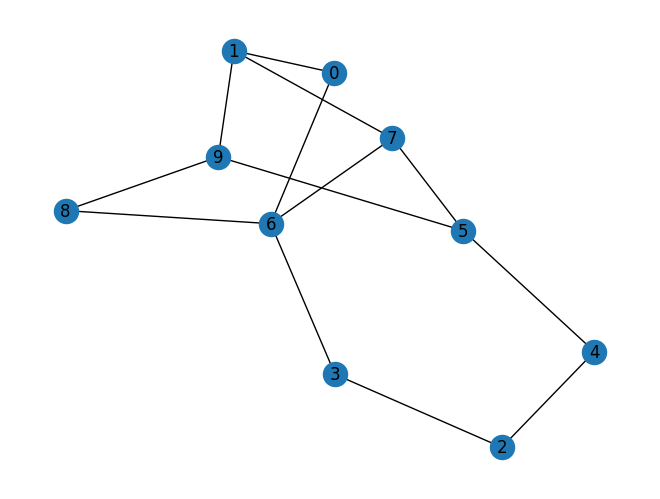

In [3]:
nx.draw(G, with_labels=True)

In [4]:
# 3d spring layout
pos = nx.spring_layout(G, dim=3, scale=50, seed=2)

# show positions
print(pos)

{0: array([ 16.96248881, -33.88276947,  15.68543146]), 1: array([  7.38898302, -34.10846433,  -8.39680514]), 2: array([ 1.2322003 , 50.        ,  6.81399805]), 3: array([ 6.345367  , 26.62967305, 23.1660199 ]), 4: array([ -5.66969136,  40.01472369, -17.62470804]), 5: array([ -6.6100095 ,   8.52816284, -22.82028414]), 6: array([ 5.15756581, -7.03498588, 17.2290831 ]), 7: array([ 9.40686814, -9.71049301, -9.88820007]), 8: array([-19.60995674, -20.70292191,  10.9506903 ]), 9: array([-14.60381548, -19.73292497, -15.11522539])}


In [5]:
z_pos = {}

for node, coords in pos.items():
  new_coords = []
  for cord in coords:
    frac_part = cord - int(cord)
    if frac_part < 0.5:
      new_coords.append( math.floor( cord ) )
    else:
      new_coords.append( math.ceil( cord ) )

  z_pos[node] = new_coords

In [6]:
z_pos

{0: [17, -34, 16],
 1: [7, -35, -9],
 2: [1, 50, 7],
 3: [6, 27, 23],
 4: [-6, 40, -18],
 5: [-7, 9, -23],
 6: [5, -8, 17],
 7: [9, -10, -10],
 8: [-20, -21, 11],
 9: [-15, -20, -16]}

[(0, 1), (0, 6), (1, 7), (1, 9), (2, 3), (2, 4), (3, 6), (4, 5), (5, 7), (5, 9), (6, 7), (6, 8), (8, 9)]


Text(0.5, 0, 'z')

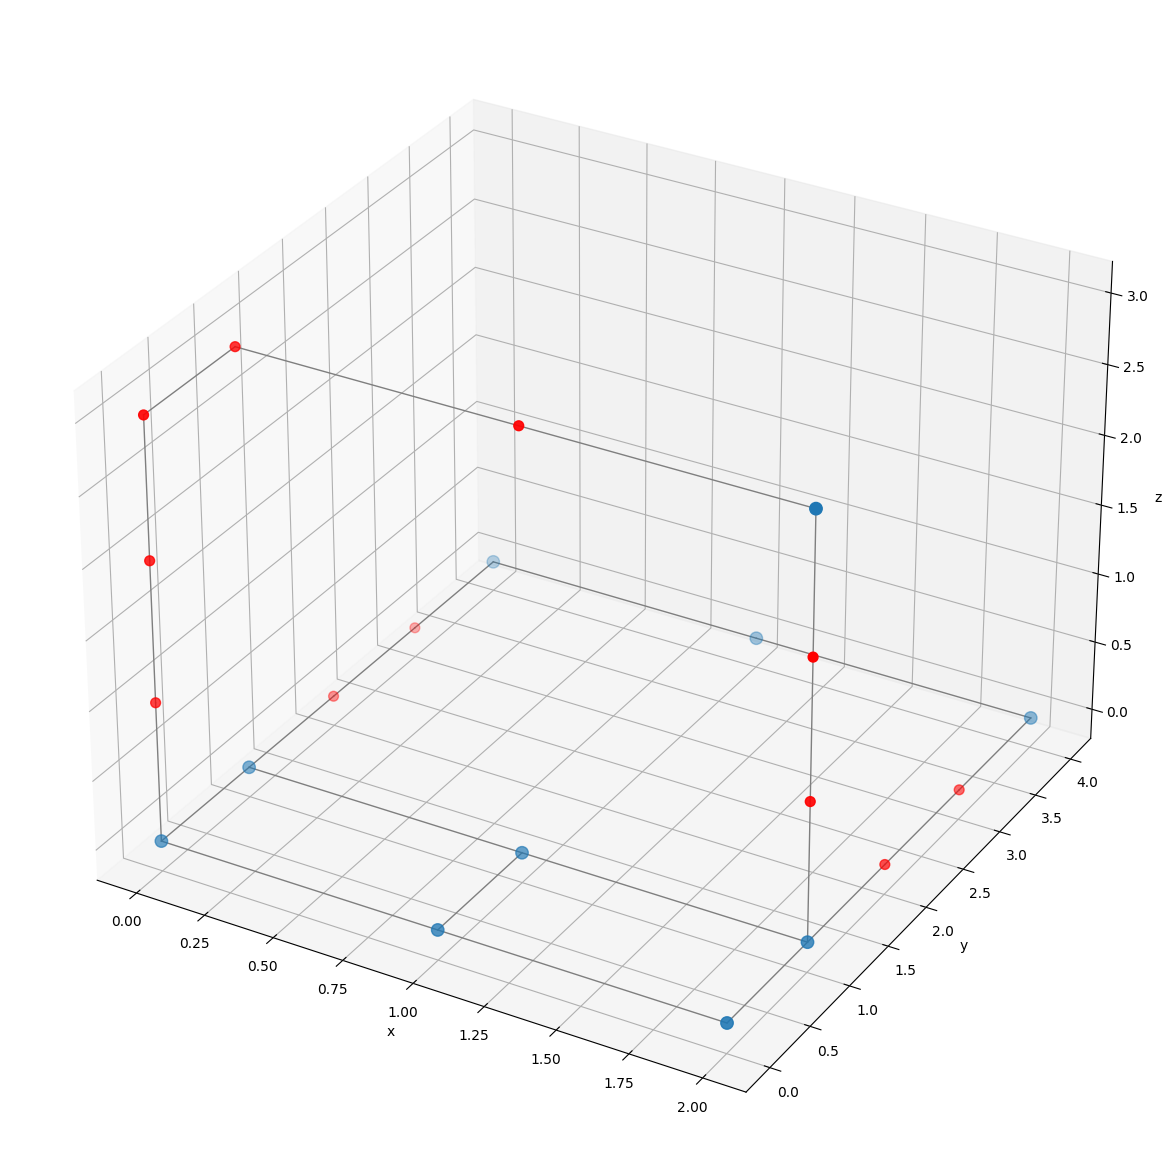

In [7]:
# Hardcoded 3d coordinates by hand

hardcoded_positions = {
  0: [2, 0, 0],
  1: [1, 0, 0],
  2: [1, 4, 0],
  3: [2, 4, 0],
  4: [0, 4, 0],
  5: [0, 1, 0],
  6: [2, 1, 0],
  7: [1, 1, 0],
  8: [2, 1, 3],
  9: [0, 0, 0]
}

aux_atoms = {
  10: [2, 2, 0],
  11: [2, 3, 0],

  12: [0, 2, 0],
  13: [0, 3, 0],

  14: [2, 1, 1],
  15: [2, 1, 2],

  16: [1, 1, 3],
  17: [0, 1, 3],
  18: [0, 0, 3],
  19: [0, 0, 2],
  20: [0, 0, 1]
}

aux_atoms_list = list(aux_atoms.keys())

all_atoms = hardcoded_positions | aux_atoms

additional_edges = [
  ( 6, 10 ),
  ( 10, 11 ),
  ( 11, 3 ),
  
  ( 5, 12 ),
  ( 12, 13 ),
  ( 13, 4 ),

  ( 6, 14 ),
  ( 14, 15 ),
  ( 15, 8 ),

  ( 8, 16 ),
  ( 16, 17 ),
  ( 17, 18 ),
  ( 18, 19 ),
  ( 19, 20 ),
  ( 20, 9 )
]

# Create the 3D figure
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection="3d")

positions_matrix = np.array( [v for _,v in hardcoded_positions.items()] )
aux_nodes = np.array( [v for _,v in aux_atoms.items()] )

# Plot the nodes - alpha is scaled by "depth" automatically
ax.scatter(*positions_matrix.T, s=80 )
ax.scatter(*aux_nodes.T, color="red", s=50)

print(G.edges())

for e in list(G.edges()) + additional_edges:
  line = []
  if e != (4,5) and e != (3,6) and e!=(6,8) and e!=(8,9):
    u = e[0]
    v = e[1]
    line = np.column_stack( ( all_atoms[u], all_atoms[v] ) )
    # print(line)
    ax.plot( *line, color='tab:gray', linewidth=1 )

# for e in additional_edges:
#   line = []
#   u = e[0]
#   v = e[1]
#   line = np.column_stack( ( all_atoms[u], all_atoms[v] ) )
#   ax.plot( *line, color='tab:gray', linewidth=1 )

ax.set_xlabel( "x" )
ax.set_ylabel( "y" )
ax.set_zlabel( "z" )

{0: [16, 0, 0], 1: [8, 0, 0], 2: [8, 32, 0], 3: [16, 32, 0], 4: [0, 32, 0], 5: [0, 8, 0], 6: [16, 8, 0], 7: [8, 8, 0], 8: [16, 8, 24], 9: [0, 0, 0], 10: [16, 16, 0], 11: [16, 24, 0], 12: [0, 16, 0], 13: [0, 24, 0], 14: [16, 8, 8], 15: [16, 8, 16], 16: [8, 8, 24], 17: [0, 8, 24], 18: [0, 0, 24], 19: [0, 0, 16], 20: [0, 0, 8]}


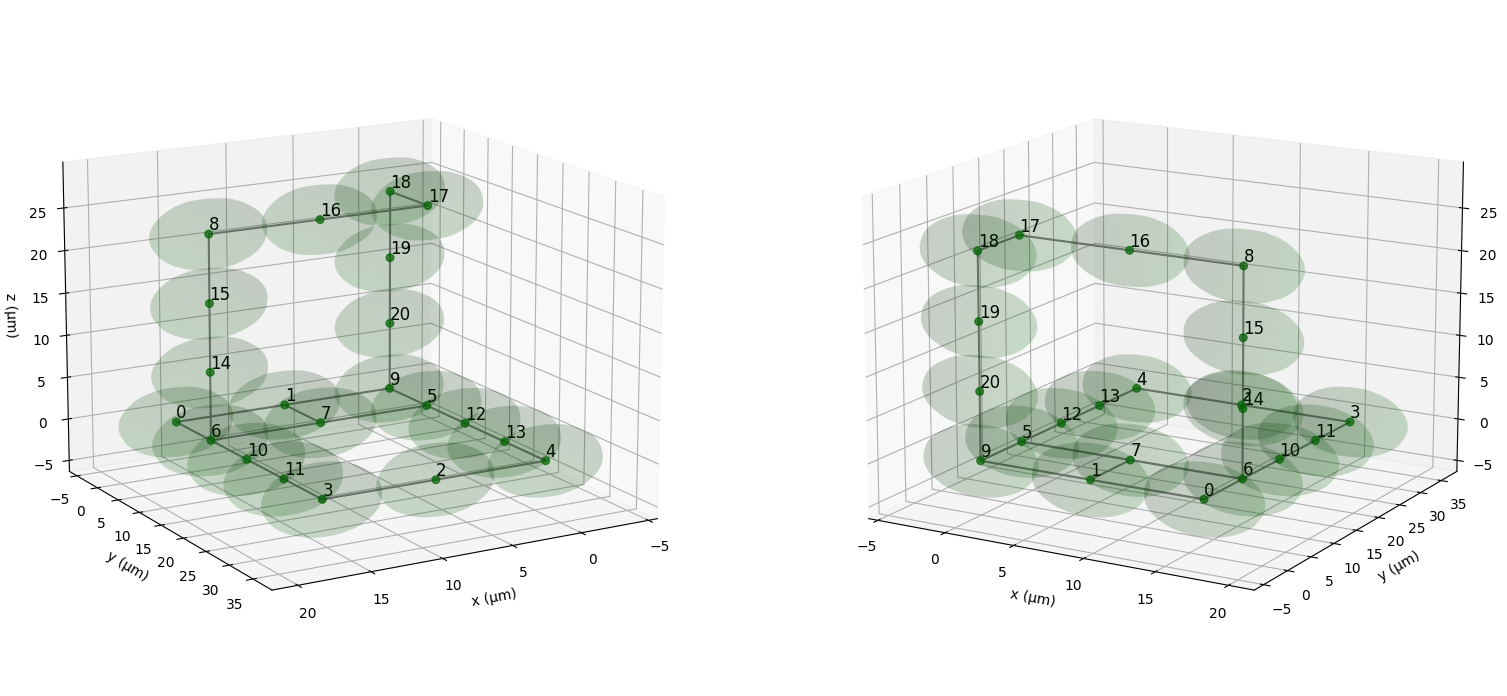

In [8]:
from pulser.register import Register3D
from pulser.sequence import Sequence
from pulser.devices import MockDevice
from pulser.waveforms import BlackmanWaveform, RampWaveform, InterpolatedWaveform
from pulser.pulse import Pulse

rescaled_atoms = {}
# Rescale coordinates
for k,v in all_atoms.items():
  rescaled_atoms[k] = [val*8 for val in v]

print(rescaled_atoms)

register = Register3D( rescaled_atoms )

register.draw( with_labels=True, blockade_radius=8, draw_half_radius=True, draw_graph=True )

In [9]:
# We choose a median value between the min and the max
Omega = MockDevice.rabi_from_blockade( 8 )

delta_0 = -5  # just has to be negative
delta_f = -delta_0  # just has to be positive
T = 4000  # time in ns, we choose a time long enough to ensure the propagation of information in the system

In [10]:
print(Omega)

20.67626392364502


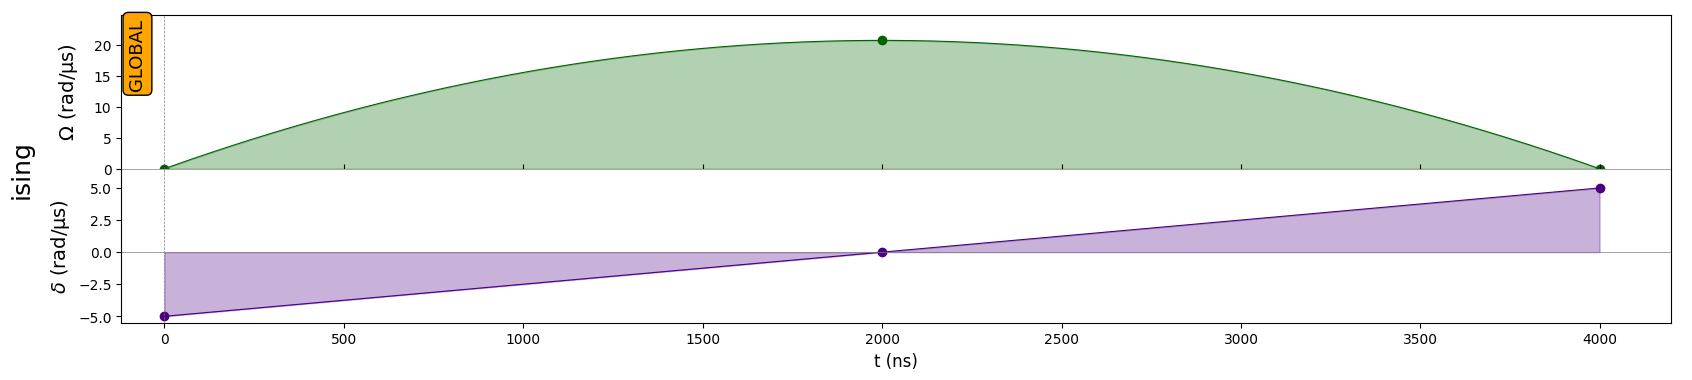

In [11]:
adiabatic_pulse = Pulse(
  InterpolatedWaveform(T, [1e-9, Omega, 1e-9]),
  InterpolatedWaveform(T, [delta_0, 0, delta_f]),
  0,
)

seq = Sequence(register, MockDevice)
seq.declare_channel("ising", "rydberg_global")
seq.add(adiabatic_pulse, "ising")
seq.draw()

In [12]:
seq.available_channels

{'rydberg_global': Rydberg.Global(Max Absolute Detuning: None, Max Amplitude: None, Clock period: 1 ns, Minimum pulse duration: 1 ns, Basis: 'ground-rydberg'),
 'rydberg_local': Rydberg.Local(Max Absolute Detuning: None, Max Amplitude: None, Minimum retarget time: 0 ns, Fixed retarget time: 0 ns, Clock period: 1 ns, Minimum pulse duration: 1 ns, Basis: 'ground-rydberg'),
 'raman_global': Raman.Global(Max Absolute Detuning: None, Max Amplitude: None, Clock period: 1 ns, Minimum pulse duration: 1 ns, Basis: 'digital'),
 'raman_local': Raman.Local(Max Absolute Detuning: None, Max Amplitude: None, Minimum retarget time: 0 ns, Fixed retarget time: 0 ns, Clock period: 1 ns, Minimum pulse duration: 1 ns, Basis: 'digital'),
 'dmm_0': DMM.Global(Max Absolute Detuning: None, Max Amplitude: 0, Clock period: 1 ns, Minimum pulse duration: 1 ns, Maximum pulse duration: 100000000 ns, Basis: 'ground-rydberg')}

In [13]:
register.qubits

{0: array([16.,  0.,  0.]),
 1: array([8., 0., 0.]),
 2: array([ 8., 32.,  0.]),
 3: array([16., 32.,  0.]),
 4: array([ 0., 32.,  0.]),
 5: array([0., 8., 0.]),
 6: array([16.,  8.,  0.]),
 7: array([8., 8., 0.]),
 8: array([16.,  8., 24.]),
 9: array([0., 0., 0.]),
 10: array([16., 16.,  0.]),
 11: array([16., 24.,  0.]),
 12: array([ 0., 16.,  0.]),
 13: array([ 0., 24.,  0.]),
 14: array([16.,  8.,  8.]),
 15: array([16.,  8., 16.]),
 16: array([ 8.,  8., 24.]),
 17: array([ 0.,  8., 24.]),
 18: array([ 0.,  0., 24.]),
 19: array([ 0.,  0., 16.]),
 20: array([0., 0., 8.])}

In [14]:
for atom in aux_atoms_list:
  seq.declare_channel("ch"+str(atom), "rydberg_local", initial_target=atom)

  simple_pulse = Pulse.ConstantPulse(4000, 0, Omega/2, 0)

  seq.add( simple_pulse, "ch"+str(atom), 'no-delay' )

In [15]:
# from pulser_simulation import QutipEmulator

# simul = QutipEmulator.from_sequence(seq, evaluation_times="Minimal")

# results = simul.run(True)

# final = results.get_final_state()
# count_dict = results.sample_final_state()

In [16]:
# Create time independent factor
qubits = register.qubits

# interactions = []

In [17]:
from qutip import *

N_qubits = len(all_atoms.keys())

init_state = basis( 2**N_qubits, 2**N_qubits-1 )

In [18]:
n = (sigmaz() + 1)/2

In [19]:
n

Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = True
Qobj data =
[[1. 0.]
 [0. 0.]]

In [20]:
amplit = InterpolatedWaveform(T, [1e-9, Omega, 1e-9])
det = InterpolatedWaveform(T, [delta_0, 0, delta_f]),

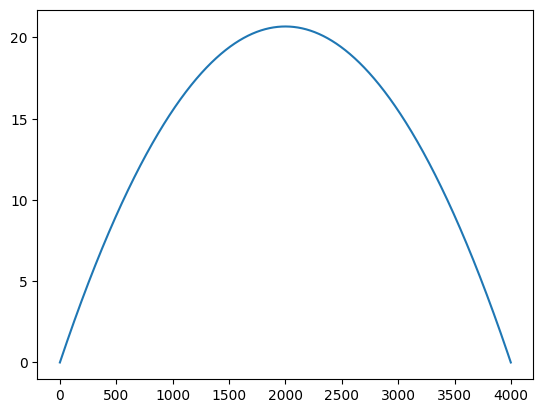

In [21]:
plt.plot( [x for x in range(T)], amplit.samples )

In [22]:
delta_t = 1e-3

In [29]:
I = qeye(2)

def H(I, n):
  H_interaction = None

  for i in range( N_qubits ):
    for j in range( N_qubits ):
      print(all_atoms[i])
      U_ij = MockDevice.interaction_coeff / np.linalg.norm( np.array(all_atoms[i]) - np.array(all_atoms[j]) )**6

      # Case i==0 and j variable
      if i==0 and j==1:
        H_temp = tensor( n, n )
        for z in range( j+1, N_qubits ):  
          H_temp = tensor( H_temp, I )
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i==0 and j==i+2:
        H_temp = tensor( n, I )
        H_temp = tensor( H_temp, n )
        for z in range( j+1, N_qubits ):  
          H_temp = tensor( H_temp, I )
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i==0:
        H_temp = tensor( n, I )
        z = i+2
        while z != j:  
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        z = j+1
        while z < N_qubits:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = U_ij * H_temp
        H_interaction += H_temp

      # Case i==1
      if i==1 and j==2:
        H_temp = tensor( I, n )
        H_temp = tensor( H_temp, n )
        for z in range( j+1, N_qubits ):  
          H_temp = tensor( H_temp, I )
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i==1 and j==i+2:
        H_temp = tensor( I, n )
        H_temp = tensor( H_temp, I )
        H_temp = tensor( H_temp, n )
        for z in range( j+1, N_qubits ):  
          H_temp = tensor( H_temp, I )
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i==1:
        H_temp = tensor( I, n )
        H_temp = tensor( H_temp, I )
        z = i+2
        while z != j:  
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        z = j+1
        while z < N_qubits:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = U_ij * H_temp
        H_interaction += H_temp


      # Case i generic
      if i!=0 and i!=1 and i!=N_qubits-2 and j == i+1:
        H_temp = tensor( I, I )
        z = 2
        while z!=i:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        H_temp = tensor( H_temp, n )
        z = j+1
        while z < N_qubits:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i!=0 and i!=1 and i!=N_qubits-2 and j == i+2:
        H_temp = tensor( I, I )
        z = 2
        while z!=i:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        H_temp = tensor( H_temp, I )
        H_temp = tensor( H_temp, n )
        z = j+1
        while z < N_qubits:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      elif i!=0 and i!=1 and i!=N_qubits-2 and j!=i+1 and j!=i+2:
        H_temp = tensor( I, I )
        z = 2
        while z!=i:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        z = i+1
        while z != j:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        z = j+1
        while z < N_qubits:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = U_ij * H_temp
        H_interaction += H_temp
      

      # Last case
      if i==N_qubits-2 and j==N_qubits-1:
        H_temp = tensor( I, I )
        z = 2
        while z!=i:
          H_temp = tensor( H_temp, I )
          z = z+1
        H_temp = tensor( H_temp, n )
        H_temp = tensor( H_temp, n )
        H_temp = U_ij * H_temp
        H_interaction += H_temp

  return H_interaction

H_interaction = H(I, n)

[2, 0, 0]


/tmp/ipykernel_12893/4141937051.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  U_ij = MockDevice.interaction_coeff / np.linalg.norm( np.array(all_atoms[i]) - np.array(all_atoms[j]) )**6


In [26]:
print(H_interaction)

None


In [ ]:
# next_state = init_state + 1e-3*( -j* )